In [1]:
import os

os.environ["HSA_OVERRIDE_GFX_VERSION"] = "10.3.0"

In [2]:
import numpy as np 

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split 

import sklearn.metrics as skm

import matplotlib.pyplot as plt

In [3]:
# Transform to turn into tensor and normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307),(0.3081,)) # mean y std
])

# Load the dataset and normalize it
train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=False,
    transform=transform
)

# Load the test dataset
test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=False,
    transform=transform
)

In [4]:
# DataLoaders
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=1028,
    num_workers=4,
    shuffle=True,
    drop_last=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=2056,
    num_workers=4,
    shuffle=True,
    drop_last=True
)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Entrenando en: {device}")

Entrenando en: cuda


In [6]:
def createTheMNISTNet():

    class mnistNet(nn.Module):
        def __init__(self):
            super().__init__()

            # input layer
            self.input = nn.Linear(784,64)

            # hidden layer
            self.fc1 = nn.Linear(64,32)
            self.fc2 = nn.Linear(32,32)

            # output layer
            self.output = nn.Linear(32,10)

        def forward(self,x):
            x = x.view(x.shape[0], -1)
            
            x = F.relu( self.input(x) )
            x = F.relu( self.fc1(x) )
            x = F.relu( self.fc2(x) )
            return self.output(x)

    net = mnistNet()

    lossfun = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(net.parameters(), lr=0.01) 

    return net, lossfun, optimizer

In [7]:
def function2trainTheModel():

    numepochs = 10

    net, lossfun, optimizer = createTheMNISTNet()
    net.to(device)

    losses = torch.zeros(numepochs)
    trainAcc = []
    testAcc = []

    for epochi in range(numepochs):

        # ===== Train =====
        batchAcc = []
        batchLoss = []
        for X,y in train_loader:

            X, y = X.to(device), y.to(device)
            
            # forward
            yHat = net(X)
            loss = lossfun(yHat, y)

            # back
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # loss
            batchLoss.append( loss.item() )

            # accuracy
            matches = torch.argmax(yHat, axis=1) == y # predictions
            matchesNumeric = matches.float() # to numeric
            accuracyPct = 100*torch.mean(matchesNumeric) # pct of mean
            batchAcc.append( accuracyPct.item() ) # add

        trainAcc.append( np.mean(batchAcc) )

        losses[epochi] = np.mean(batchLoss)

        # ===== Test =====
        X,y = next(iter(test_loader))
        X, y = X.to(device), y.to(device)
        yHat = net(X)

        acc = 100*torch.mean( (torch.argmax(yHat, axis=1)==y).float() )
        testAcc.append( acc.item() )
        
        print(f'Epoch: {epochi} \f trainAcc: {trainAcc[epochi]} \f testAcc: {testAcc[epochi]}')

    return trainAcc, testAcc, losses, net

In [ ]:
trainAcc, testAcc, losses, net = function2trainTheModel()

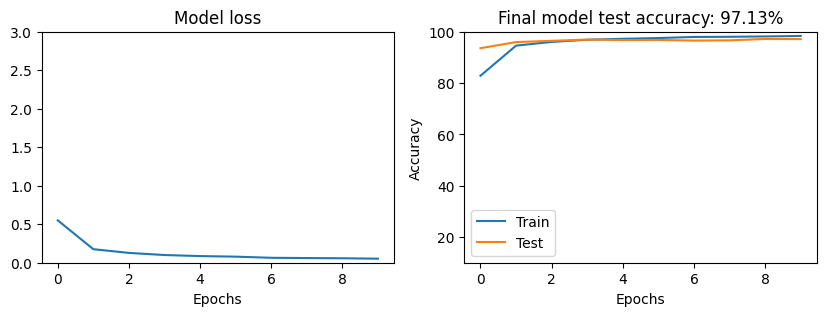

In [9]:
fig, ax = plt.subplots(1,2,figsize=(10,3))

ax[0].plot(losses)
ax[0].set_xlabel('Epochs')
ax[0].set_ylim([0,3])
ax[0].set_title('Model loss')

ax[1].plot(trainAcc, label='Train')
ax[1].plot(testAcc, label='Test')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Accuracy')
ax[1].set_ylim([10, 100])
ax[1].set_title(f'Final model test accuracy: {testAcc[-1]:.2f}%')
ax[1].legend()

In [10]:
yHat = net(train_loader.dataset.tensor[0])
train_predictions = torch.argmax(yHat, axis=1)

yHat = net(test_loader.dataset.tensor[0])
test_predictions = torch.argmax(yHat, axis=1)
test_predictions 

AttributeError: 'MNIST' object has no attribute 'tensor'

In [11]:
# average = None, weighted and macro
skm1 = skm.precision_score(train_loader.dataset.tensors[1], train_predictions, average=None)
skm2 = skm.precision_score(train_loader.dataset.tensors[1], train_predictions, average=None)
skm3 = skm.precision_score(train_loader.dataset.tensors[1], train_predictions, average=None)

print(skm1)
print(skm2)
print(skm3)

AttributeError: 'MNIST' object has no attribute 'tensors'

In [12]:
import sklearn.metrics as skm

train_metrics = [0,0,0,0]
test_metrics = [0,0,0,0]

train_metrics[0] = skm.accuracy_score(train_loader.dataset.tensors[1].cpu(), train_predictions.cpu()>0)
train_metrics[1] = skm.precision_score(train_loader.dataset.tensors[1].cpu(), train_predictions.cpu()>0)
train_metrics[2] = skm.recall_score(train_loader.dataset.tensors[1].cpu(), train_predictions.cpu()>0)
train_metrics[3] = skm.f1_score(train_loader.dataset.tensors[1].cpu(), train_predictions.cpu()>0)

test_metrics[0] = skm.accuracy_score(test_loader.dataset.tensors[1].cpu(), test_predictions.cpu() > 0)
test_metrics[1] = skm.precision_score(test_loader.dataset.tensors[1].cpu(), test_predictions.cpu() > 0)
test_metrics[2] = skm.recall_score(test_loader.dataset.tensors[1].cpu(), test_predictions.cpu() > 0)
test_metrics[3] = skm.f1_score(test_loader.dataset.tensors[1].cpu(), test_predictions.cpu() > 0)

AttributeError: 'MNIST' object has no attribute 'tensors'

In [13]:
torch.save( net.state_dict(), 'mnist_model.pth')